<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/5_gravity_cosmo_strings/string_theory/string_ch04_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*String Theory* — `string_ch04_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# String Theory Ch 4 — Figure Notebook
**Conformal Field Theory**

In [1]:
FIG_DIR = 'figures/ch04'

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os

BG='#1e1e2e';FG='#cdd6f4';EDGE='#45475a'
SKYB='#89c4f4';YELL='#f9c74f';GREEN='#90ee90'
RED='#e07070';PURP='#c792ea';ORAN='#e8a838';TEAL='#2ec4b6'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,
    'text.color':FG,'axes.labelcolor':FG,
    'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.25,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':SKYB,'legend.framealpha':0.3,
    'legend.edgecolor':EDGE,'lines.linewidth':2.2,
    'axes.linewidth':1.2,'figure.dpi':110,
})
os.makedirs(FIG_DIR, exist_ok=True)

def save(name, fig):
    fig.savefig(f'{FIG_DIR}/{name}', dpi=150, bbox_inches='tight', facecolor=BG)
    plt.show(); print(f'Saved: {FIG_DIR}/{name}')

print('Setup complete.')


Setup complete.


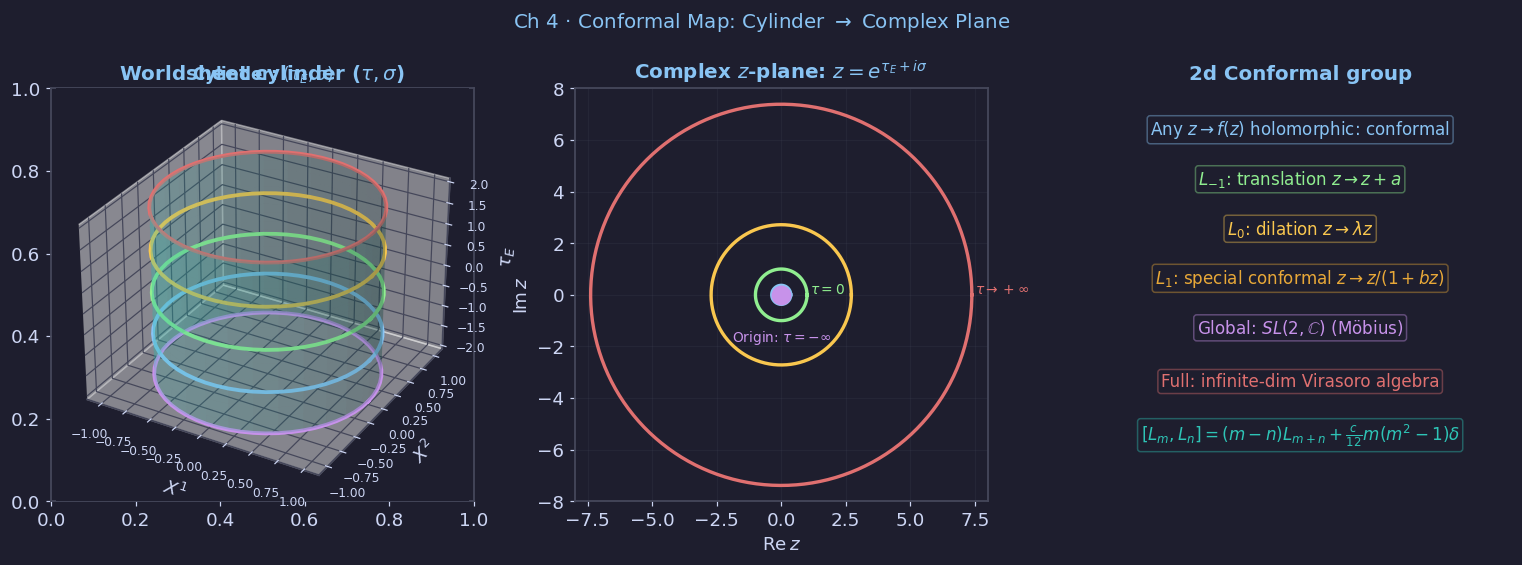

Saved: figures/ch04/fig01_cft_cylinder_plane.png


In [2]:

# ── fig01: Cylinder to complex plane mapping ─────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle(r'Ch 4 · Conformal Map: Cylinder $\to$ Complex Plane',
             color=SKYB, fontsize=13)

# Left: cylinder
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'Worldsheet cylinder ($\tau,\sigma$)', color=SKYB)
from mpl_toolkits.mplot3d import Axes3D  # noqa
ax = fig.add_subplot(1,3,1, projection='3d')
ax.set_facecolor(BG)
theta = np.linspace(0, 2*np.pi, 60)
z_cyl = np.linspace(-2, 2, 20)
TH, ZC = np.meshgrid(theta, z_cyl)
XC = np.cos(TH)
YC = np.sin(TH)
ax.plot_surface(XC, YC, ZC, alpha=0.2, color=TEAL)
# Time slices
for z_val, col in [(-2, PURP), (-1, SKYB), (0, GREEN), (1, YELL), (2, RED)]:
    ax.plot(np.cos(theta), np.sin(theta), z_val, color=col, lw=2.5)
ax.set_xlabel(r'$X^1$'); ax.set_ylabel(r'$X^2$'); ax.set_zlabel(r'$\tau_E$')
ax.set_title(r'Cylinder: $(\tau_E,\sigma)$', color=SKYB, fontsize=11)
ax.tick_params(labelsize=8)

# Middle: complex z-plane
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r'Complex $z$-plane: $z=e^{\tau_E+i\sigma}$', color=SKYB)
# Draw circles (time slices)
for r_val, col, lbl in [#(np.e**(-2),  PURP, r'$\tau\to-\infty$'),
                         (np.e**(-1), SKYB, ''),
                         (1.0,        GREEN,r'$\tau=0$'),
                         (np.e**(1),  YELL, ''),
                         (np.e**(2),  RED,  r'$\tau\to+\infty$')]:
    th = np.linspace(0, 2*np.pi, 300)
    ax2.plot(r_val*np.cos(th), r_val*np.sin(th), color=col, lw=2.2)
    if lbl:
        ax2.text(r_val+0.12, 0.05, lbl, color=col, fontsize=9)
ax2.plot(0, 0, 'o', color=PURP, ms=12, zorder=8)
ax2.text(-1.9, -1.8, r'Origin: $\tau=-\infty$', color=PURP, fontsize=9)
ax2.set_xlim(-8, 8); ax2.set_ylim(-8, 8)
ax2.set_xlabel(r'$\mathrm{Re}\,z$'); ax2.set_ylabel(r'$\mathrm{Im}\,z$')
ax2.grid(True, alpha=0.2); ax2.set_aspect('equal')

# Right: conformal group
ax3 = axes[2]; ax3.set_facecolor(BG); ax3.axis('off')
ax3.set_title('2d Conformal group', color=SKYB)
items = [
    (0.5, 0.90, r'Any $z\to f(z)$ holomorphic: conformal', SKYB),
    (0.5, 0.78, r'$L_{-1}$: translation $z\to z+a$', GREEN),
    (0.5, 0.66, r'$L_0$: dilation $z\to\lambda z$', YELL),
    (0.5, 0.54, r'$L_1$: special conformal $z\to z/(1+bz)$', ORAN),
    (0.5, 0.42, r'Global: $SL(2,\mathbb{C})$ (Möbius)', PURP),
    (0.5, 0.29, r'Full: infinite-dim Virasoro algebra', RED),
    (0.5, 0.16, r'$[L_m,L_n]=(m-n)L_{m+n}+\frac{c}{12}m(m^2-1)\delta$', TEAL),
]
for x_,y_,txt,col in items:
    ax3.text(x_,y_,txt,ha='center',va='center',fontsize=11,color=col,
             transform=ax3.transAxes,
             bbox=dict(boxstyle='round,pad=0.18',fc=BG,ec=col,alpha=0.4))

plt.tight_layout()
save('fig01_cft_cylinder_plane.png', fig)


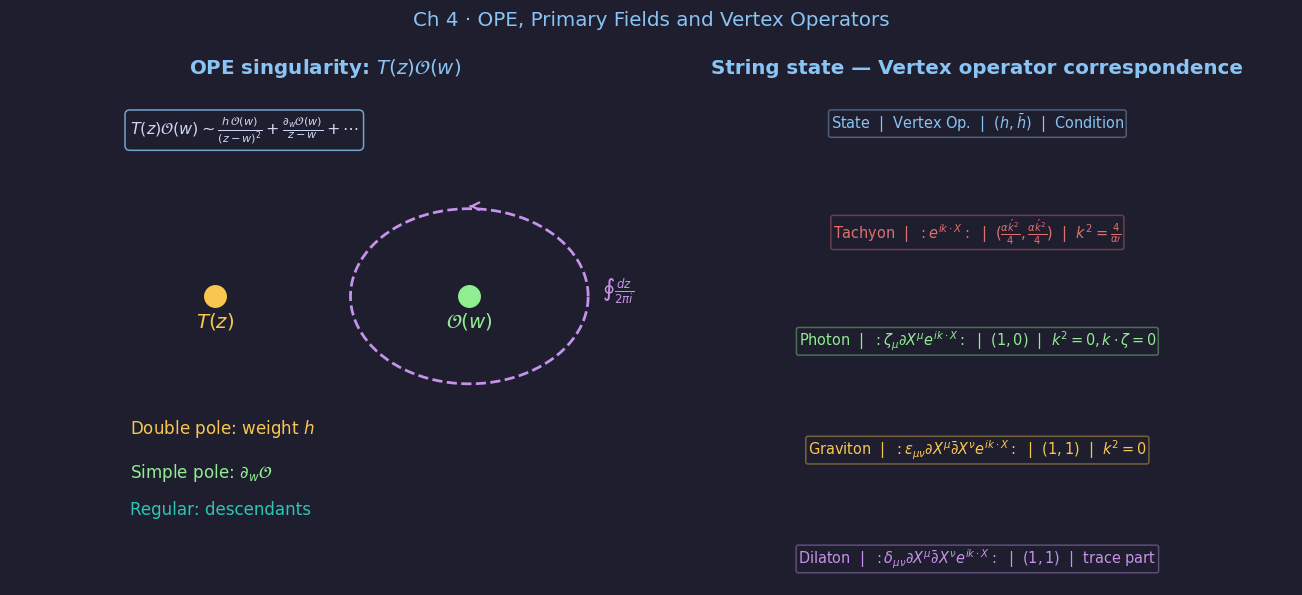

Saved: figures/ch04/fig02_ope_vertex_operators.png


In [3]:

# ── fig02: OPE structure and primary fields ───────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle('Ch 4 · OPE, Primary Fields and Vertex Operators', color=SKYB, fontsize=13)

# Left: OPE singularity structure
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'OPE singularity: $T(z)\mathcal{O}(w)$', color=SKYB)
ax.set_xlim(-0.2, 3.5); ax.set_ylim(-0.5, 3.5); ax.axis('off')

# Draw z and w points
ax.plot([1.0],[1.8],'o', color=YELL, ms=14, zorder=8)
ax.text(1.0, 1.55, r'$T(z)$', ha='center', color=YELL, fontsize=13)
ax.plot([2.5],[1.8],'o', color=GREEN, ms=14, zorder=8)
ax.text(2.5, 1.55, r'$\mathcal{O}(w)$', ha='center', color=GREEN, fontsize=13)

# Contour around w
th = np.linspace(0, 2*np.pi, 200)
ax.plot(2.5 + 0.7*np.cos(th), 1.8 + 0.7*np.sin(th),
        color=PURP, lw=1.8, ls='--')
ax.annotate('', xy=(2.5, 2.52), xytext=(2.5+0.01, 2.52),
            arrowprops=dict(arrowstyle='->', color=PURP, lw=1.5))
ax.text(2.5+0.78, 1.8, r'$\oint \frac{dz}{2\pi i}$', color=PURP, fontsize=11)

# OPE terms
ax.text(0.5, 3.1, r'$T(z)\mathcal{O}(w)\sim\frac{h\,\mathcal{O}(w)}{(z-w)^2}+\frac{\partial_w\mathcal{O}(w)}{z-w}+\cdots$',
        ha='left', fontsize=10.5, color=FG,
        bbox=dict(boxstyle='round', fc=BG, ec=SKYB, alpha=0.8))

ax.text(0.5, 0.7, r'Double pole: weight $h$', color=YELL, fontsize=11)
ax.text(0.5, 0.35, r'Simple pole: $\partial_w\mathcal{O}$', color=GREEN, fontsize=11)
ax.text(0.5, 0.05, r'Regular: descendants', color=TEAL, fontsize=11)

# Right: vertex operators table
ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title('String state — Vertex operator correspondence', color=SKYB)

rows = [
    ('State', 'Vertex Op.', r'$(h,\bar h)$', 'Condition'),
    ('Tachyon', r'$:e^{ik\cdot X}:$',
     r'$(\frac{\alpha\'k^2}{4},\frac{\alpha\'k^2}{4})$', r'$k^2=\frac{4}{\alpha\prime}$'),
    ('Photon', r'$:\zeta_\mu\partial X^\mu e^{ik\cdot X}:$',
     r'$(1, 0)$', r'$k^2=0, k\cdot\zeta=0$'),
    ('Graviton', r'$:\epsilon_{\mu\nu}\partial X^\mu\bar\partial X^\nu e^{ik\cdot X}:$',
     r'$(1,1)$', r'$k^2=0$'),
    ('Dilaton', r'$:\delta_{\mu\nu}\partial X^\mu\bar\partial X^\nu e^{ik\cdot X}:$',
     r'$(1,1)$', r'trace part'),
]
ys2 = np.linspace(0.92, 0.05, len(rows))
cols_r = [SKYB, RED, GREEN, YELL, PURP]
for (row, y, col) in zip(rows, ys2, cols_r):
    txt = '  |  '.join(row)
    ax2.text(0.5, y, txt, ha='center', va='center', fontsize=9.5,
             color=col, transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.15', fc=BG, ec=col, alpha=0.4))

plt.tight_layout()
save('fig02_ope_vertex_operators.png', fig)


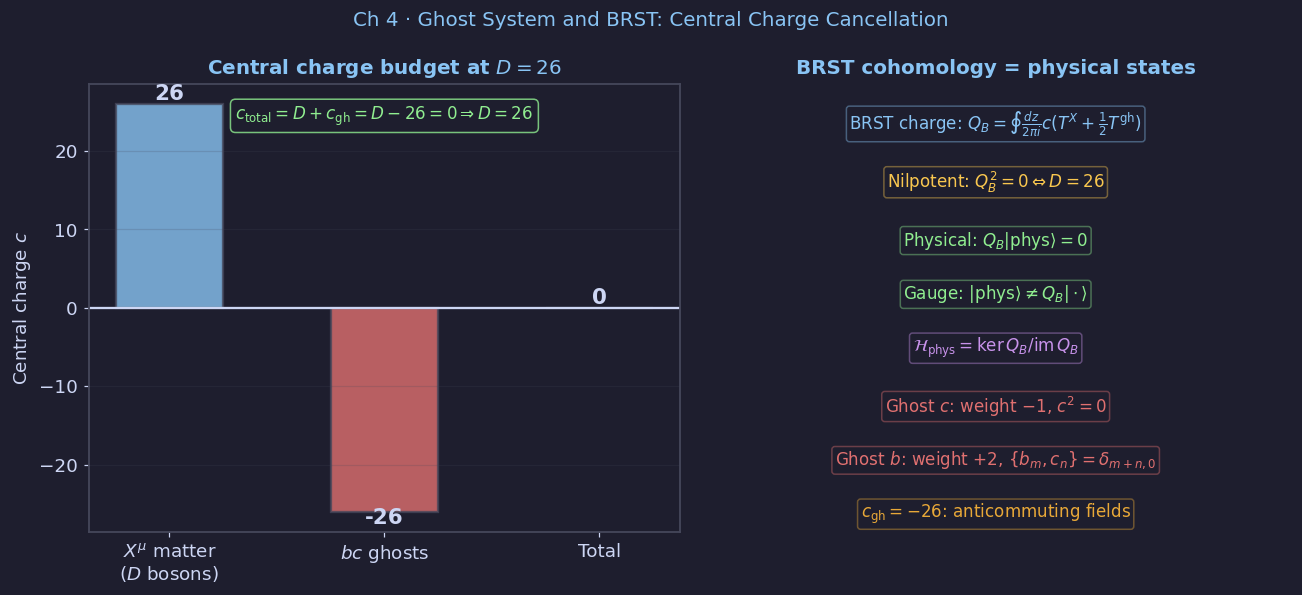

Saved: figures/ch04/fig03_ghost_brst.png


In [4]:

# ── fig03: Ghost system and BRST ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle('Ch 4 · Ghost System and BRST: Central Charge Cancellation',
             color=SKYB, fontsize=13)

# Left: central charge budget
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title('Central charge budget at $D=26$', color=SKYB)

categories = [r'$X^\mu$ matter' +'\n' +r'($D$ bosons)', r'$bc$ ghosts', 'Total']
values = [26, -26, 0]
colors_bar = [SKYB, RED, GREEN]
bars = ax.bar(categories, values, color=colors_bar, alpha=0.8,
              edgecolor=EDGE, linewidth=1.5, width=0.5)
for bar, val in zip(bars, values):
    ypos = val + 0.5 if val >= 0 else val - 1.5
    ax.text(bar.get_x()+bar.get_width()/2, ypos,
            str(val), ha='center', fontsize=14, color=FG, fontweight='bold')
ax.axhline(0, color=FG, lw=1.5)
ax.set_ylabel('Central charge $c$')
ax.grid(True, alpha=0.2, axis='y')
ax.text(0.5, 0.92,
        r'$c_{\rm total}=D+c_{\rm gh}=D-26=0\Rightarrow D=26$',
        transform=ax.transAxes, ha='center', fontsize=11, color=GREEN,
        bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.8))

# Right: BRST cohomology
ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title(r'BRST cohomology = physical states', color=SKYB)
items = [
    (0.5, 0.91, r'BRST charge: $Q_B=\oint\frac{dz}{2\pi i}c(T^X+\frac{1}{2}T^{\rm gh})$', SKYB),
    (0.5, 0.78, r'Nilpotent: $Q_B^2=0 \Leftrightarrow D=26$', YELL),
    (0.5, 0.65, r'Physical: $Q_B|\mathrm{phys}\rangle=0$', GREEN),
    (0.5, 0.53, r'Gauge: $|\mathrm{phys}\rangle\neq Q_B|\cdot\rangle$', GREEN),
    (0.5, 0.41, r'$\mathcal{H}_{\rm phys}=\ker Q_B/{\rm im}\,Q_B$', PURP),
    (0.5, 0.28, r'Ghost $c$: weight $-1$, $c^2=0$', RED),
    (0.5, 0.16, r'Ghost $b$: weight $+2$, $\{b_m,c_n\}=\delta_{m+n,0}$', RED),
    (0.5, 0.04, r'$c_{\rm gh}=-26$: anticommuting fields', ORAN),
]
for x_,y_,txt,col in items:
    ax2.text(x_,y_,txt,ha='center',va='center',fontsize=11,color=col,
             transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.18',fc=BG,ec=col,alpha=0.4))

plt.tight_layout()
save('fig03_ghost_brst.png', fig)


In [5]:
# ── Download all figures as a zip ────────────────────────────────────────
import shutil

shutil.make_archive('ch04_figures', 'zip', 'figures/ch04')

try:
    from google.colab import files
    files.download('ch04_figures.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — figures saved to figures/ch04/')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered.
